In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, linregress, ttest_ind
import warnings
warnings.filterwarnings('ignore')

# === 1. DATA INGESTION & SETUP ===
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# Caricamento dei dataset con low_memory=False per evitare DtypeWarning
df_hcqo_raw = pd.read_csv('OECD.ELS.HD,DSD_HCQO@DF_HCQO,+all.csv', low_memory=False)
df_hosp_raw = pd.read_csv('OECD.ELS.HD,DSD_HEALTH_REAC_HOSP@DF_HOSP_REAC,+all.csv', low_memory=False)

# Ridenominazione colonne per comodità e definizione target
rename_dict = {'REF_AREA': 'Country_ISO', 'TIME_PERIOD': 'Year', 'OBS_VALUE': 'Value'}
df_hcqo = df_hcqo_raw.rename(columns=rename_dict)
df_hosp = df_hosp_raw.rename(columns=rename_dict)
target_countries = ['ITA', 'DNK']

print("Dati caricati con successo!")

Dati caricati con successo!


In [11]:
# === SEZIONE 2: PREPROCESSING E STATISTICA INFERENZIALE ===

# --- 2.1 Rigorous Preprocessing (Avoiding Simpson's Paradox) ---
# Filter Beds: Target 'Per 1000 inhabitants' and extract the national aggregate (max value)
mask_hosp = (df_hosp['Country_ISO'].isin(target_countries)) & (df_hosp['UNIT_MEASURE'] == '10P3HB') 
df_beds = df_hosp[mask_hosp][['Country_ISO', 'Year', 'Value']].rename(columns={'Value': 'Hospital_Beds_Density'})
df_beds = df_beds.groupby(['Country_ISO', 'Year'])['Hospital_Beds_Density'].max().reset_index()

# Filter Mortality: Target purely AMI methodology
mask_hcqo = (df_hcqo['Country_ISO'].isin(target_countries)) & (df_hcqo['MEASURE'].str.contains('MORTAMI', na=False))
df_ami = df_hcqo[mask_hcqo].copy()
if 'SEX' in df_ami.columns:
    df_ami = df_ami[df_ami['SEX'].isin(['_T', 'TOT', 'Total'])]
df_ami = df_ami[['Country_ISO', 'Year', 'Value']].rename(columns={'Value': 'AMI_Mortality_Rate'})
df_ami = df_ami.groupby(['Country_ISO', 'Year'])['AMI_Mortality_Rate'].mean().reset_index()

# Integration
df_master = pd.merge(df_beds, df_ami, on=['Country_ISO', 'Year'], how='inner')
df_master = df_master[(df_master['Year'] >= 2005) & (df_master['Year'] <= 2020)].reset_index(drop=True)


# --- 2.2 Inferential Statistics (OLS & Correlations) ---
stats_results = []
for country in target_countries:
    df_c = df_master[df_master['Country_ISO'] == country]
    
    val_start_b, val_end_b = df_c.iloc[0]['Hospital_Beds_Density'], df_c.iloc[-1]['Hospital_Beds_Density']
    val_start_a, val_end_a = df_c.iloc[0]['AMI_Mortality_Rate'], df_c.iloc[-1]['AMI_Mortality_Rate']
    
    r_val, p_val = pearsonr(df_c['Hospital_Beds_Density'], df_c['AMI_Mortality_Rate'])
    slope, intcpt, r_v, p_v, std_err = linregress(df_c['Hospital_Beds_Density'], df_c['AMI_Mortality_Rate'])
    
    stats_results.append({
        'Country': country,
        'Delta_%_Beds': ((val_end_b - val_start_b) / val_start_b) * 100,
        'Delta_%_Mortality': ((val_end_a - val_start_a) / val_start_a) * 100,
        'Pearson_r': r_val,
        'OLS_Slope': slope
    })
df_stats = pd.DataFrame(stats_results)


# --- 2.3 Hypothesis Testing (Welch's T-Test) ---
ita_ami = df_master[df_master['Country_ISO'] == 'ITA']['AMI_Mortality_Rate']
dnk_ami = df_master[df_master['Country_ISO'] == 'DNK']['AMI_Mortality_Rate']
t_stat_ami, p_val_ami = ttest_ind(ita_ami, dnk_ami, equal_var=False)

print("--- Risultati Statistiche Inferenziali (Gerarchia Aggiornata) ---")
print(df_stats)

--- Risultati Statistiche Inferenziali (Gerarchia Aggiornata) ---
  Country  Delta_%_Beds  Delta_%_Mortality  Pearson_r  OLS_Slope
0     ITA    -20.843672         -18.610747   0.884132   2.075290
1     DNK    -32.901554         -52.276065   0.494326   0.890285


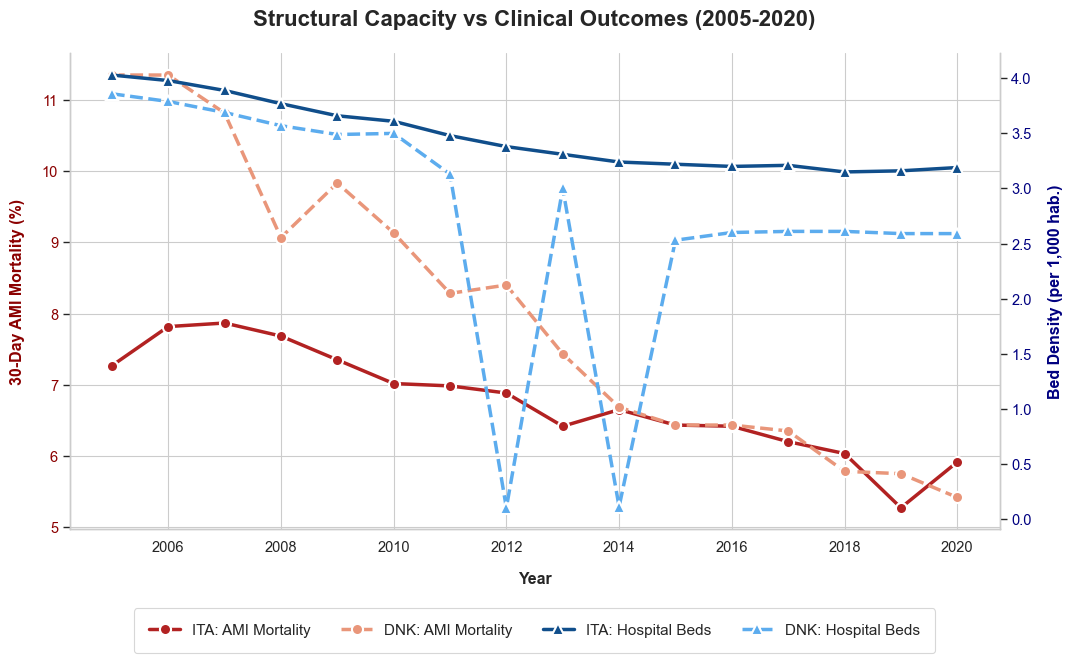

In [12]:
# === SEZIONE 3: GRAFICO 1 (Dual-Axis Time Series) ===
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Stile generale più pulito
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# Dimensioni più ampie per far respirare gli elementi
fig, ax1 = plt.subplots(figsize=(12, 7)) 

# Palette colori professionale
color_mort_ita = '#B22222' # Rosso scuro elegante
color_mort_dnk = '#E9967A' # Salmone scuro per contrasto
color_beds_ita = '#104E8B' # Blu istituzionale
color_beds_dnk = '#5CACEE' # Azzurro per contrasto

# Filtraggio Dati
df_ita = df_master[df_master['Country_ISO'] == 'ITA']
df_dnk = df_master[df_master['Country_ISO'] == 'DNK']

# --- ASSI Y SINISTRO (Mortalità) ---
ax1.set_xlabel('Year', fontweight='bold', labelpad=12)
ax1.set_ylabel('30-Day AMI Mortality (%)', color='#8B0000', fontweight='bold', labelpad=12)

l1 = ax1.plot(df_ita['Year'], df_ita['AMI_Mortality_Rate'], 
              color=color_mort_ita, marker='o', markersize=8, linewidth=2.5, 
              markeredgecolor='white', markeredgewidth=1.5, label='ITA: AMI Mortality')
l2 = ax1.plot(df_dnk['Year'], df_dnk['AMI_Mortality_Rate'], 
              color=color_mort_dnk, marker='o', markersize=8, linewidth=2.5, linestyle='--', 
              markeredgecolor='white', markeredgewidth=1.5, label='DNK: AMI Mortality')

ax1.tick_params(axis='y', labelcolor='#8B0000')

# Forza l'asse X a mostrare solo anni interi
ax1.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))


# --- ASSI Y DESTRO (Posti Letto) ---
ax2 = ax1.twinx()
ax2.set_ylabel('Bed Density (per 1,000 hab.)', color='#000080', fontweight='bold', labelpad=12)

l3 = ax2.plot(df_ita['Year'], df_ita['Hospital_Beds_Density'], 
              color=color_beds_ita, marker='^', markersize=9, linewidth=2.5, 
              markeredgecolor='white', markeredgewidth=1.5, label='ITA: Hospital Beds')
l4 = ax2.plot(df_dnk['Year'], df_dnk['Hospital_Beds_Density'], 
              color=color_beds_dnk, marker='^', markersize=9, linewidth=2.5, linestyle='--', 
              markeredgecolor='white', markeredgewidth=1.5, label='DNK: Hospital Beds')

ax2.tick_params(axis='y', labelcolor='#000080')
ax2.grid(False) # Rimuove la griglia secondaria per evitare sovrapposizioni caotiche


# --- TITOLO E LEGENDA ---
plt.title('Structural Capacity vs Clinical Outcomes (2005-2020)', fontsize=16, fontweight='bold', pad=20)

# Unisce le linee per una legenda unica
lines = l1 + l2 + l3 + l4
labels = [l.get_label() for l in lines]

# Aggiunge spazio in basso al grafico per ospitare la legenda senza tagli
fig.subplots_adjust(bottom=0.2)

# Legenda stilizzata, distanziata (bbox_to_anchor) e con bordo leggero
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.15), 
           ncol=4, frameon=True, framealpha=0.9, edgecolor='lightgrey', 
           fontsize=11, borderpad=1)

# Pulizia dei bordi (top rimosso)
sns.despine(right=False, top=True)

plt.show()

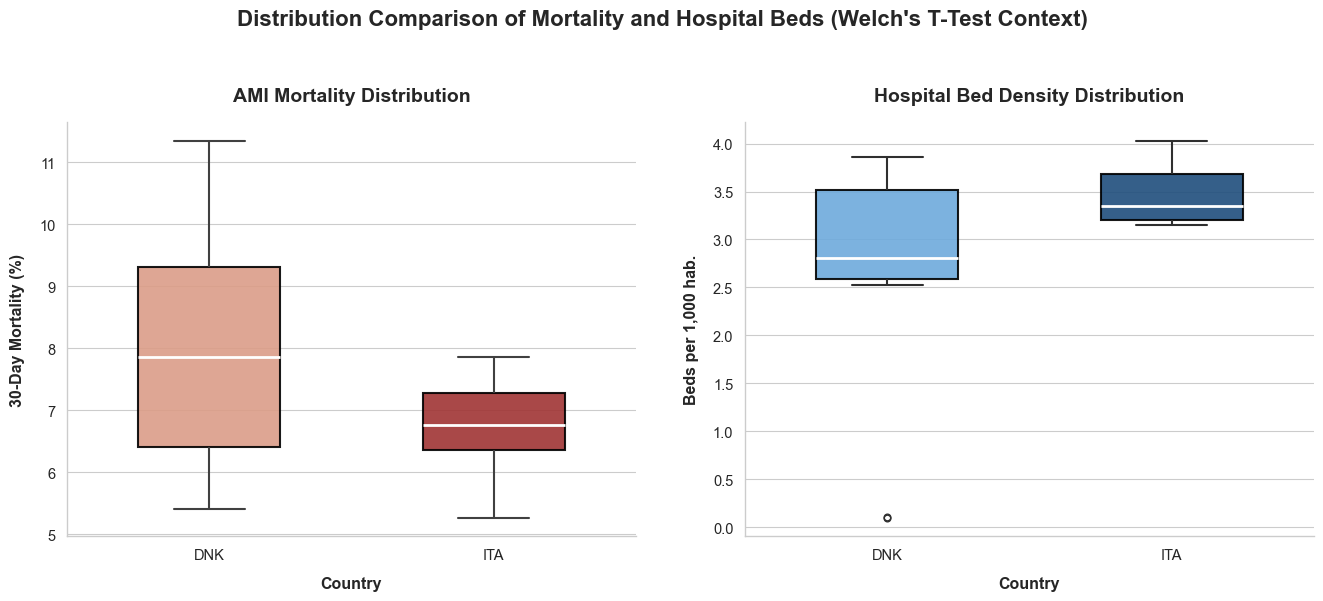

In [13]:
# === SEZIONE 4: GRAFICO 2 (Distribution Boxplots) ===
import matplotlib.pyplot as plt
import seaborn as sns

# Stile generale
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# Creazione della figura con 2 subplots affiancati
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Palette colori coerente con il Grafico 1
palette_mortality = {'DNK': '#E9967A', 'ITA': '#B22222'}
palette_beds = {'DNK': '#5CACEE', 'ITA': '#104E8B'}

# --- Boxplot 1: Mortalità AMI ---
sns.boxplot(data=df_master, x='Country_ISO', y='AMI_Mortality_Rate', 
            ax=axes[0], palette=palette_mortality, width=0.5, 
            boxprops=dict(alpha=0.9, edgecolor='black', linewidth=1.5),
            medianprops=dict(color='white', linewidth=2),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5))

axes[0].set_title('AMI Mortality Distribution', fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel('30-Day Mortality (%)', fontweight='bold', labelpad=10)
axes[0].set_xlabel('Country', fontweight='bold', labelpad=10)


# --- Boxplot 2: Densità Posti Letto ---
sns.boxplot(data=df_master, x='Country_ISO', y='Hospital_Beds_Density', 
            ax=axes[1], palette=palette_beds, width=0.5,
            boxprops=dict(alpha=0.9, edgecolor='black', linewidth=1.5),
            medianprops=dict(color='white', linewidth=2),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5))

axes[1].set_title('Hospital Bed Density Distribution', fontsize=14, fontweight='bold', pad=15)
axes[1].set_ylabel('Beds per 1,000 hab.', fontweight='bold', labelpad=10)
axes[1].set_xlabel('Country', fontweight='bold', labelpad=10)

# Pulizia dei bordi e ottimizzazione spazi
sns.despine()
plt.tight_layout(pad=3.0)

# Super-titolo per l'intera figura (incluso il contesto del T-Test come da report)
plt.suptitle("Distribution Comparison of Mortality and Hospital Beds (Welch's T-Test Context)", 
             fontsize=16, fontweight='bold', y=1.05)

plt.show()

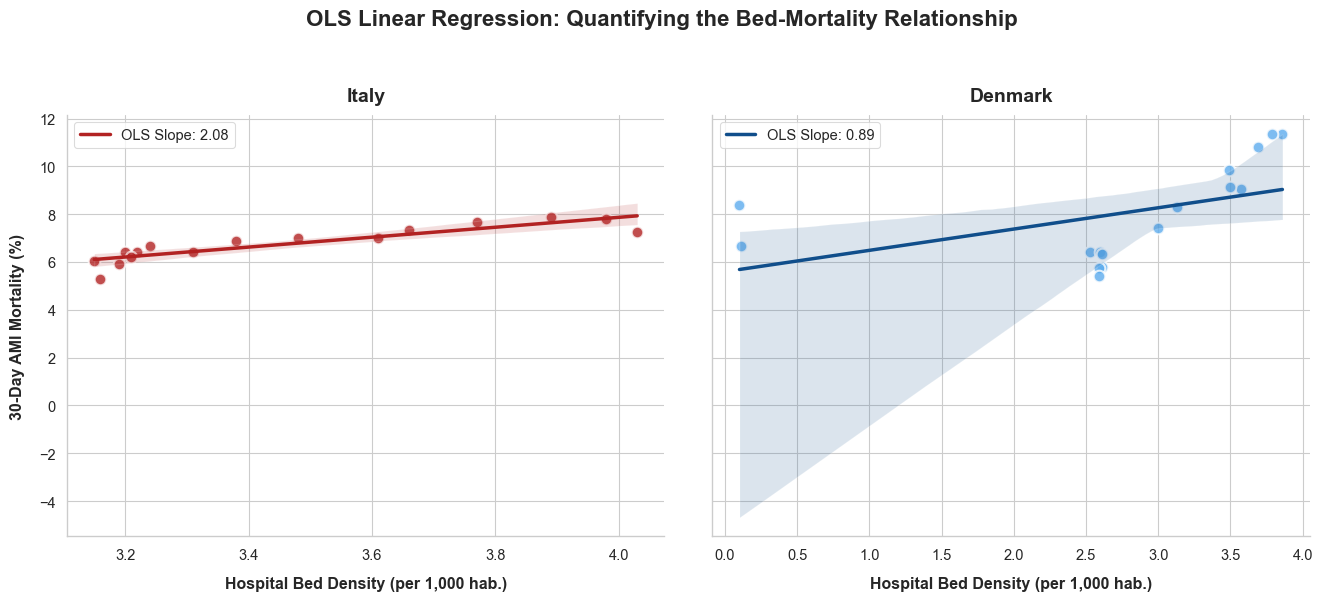

In [17]:
# === SEZIONE 5: GRAFICO 3 (Scatterplots & OLS Regression) ===
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# Creazione figura con asse Y condiviso per un confronto visivo onesto
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

df_ita = df_master[df_master['Country_ISO'] == 'ITA']
df_dnk = df_master[df_master['Country_ISO'] == 'DNK']

# Estrazione dinamica delle pendenze (slope) calcolate in precedenza
slope_ita = df_stats[df_stats['Country'] == 'ITA']['OLS_Slope'].values[0]
slope_dnk = df_stats[df_stats['Country'] == 'DNK']['OLS_Slope'].values[0]

# --- Regressione Italia ---
sns.regplot(data=df_ita, x='Hospital_Beds_Density', y='AMI_Mortality_Rate', 
            ax=axes[0], color='#B22222', 
            scatter_kws={'s': 70, 'edgecolors': 'white', 'linewidths': 1.5, 'alpha': 0.8},
            line_kws={'linewidth': 2.5, 'label': f'OLS Slope: {slope_ita:.2f}'})

axes[0].set_title(f'Italy', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('30-Day AMI Mortality (%)', fontweight='bold', labelpad=10)
axes[0].set_xlabel('Hospital Bed Density (per 1,000 hab.)', fontweight='bold', labelpad=10)
axes[0].legend(loc='upper left', frameon=True, edgecolor='lightgrey')


# --- Regressione Danimarca ---
sns.regplot(data=df_dnk, x='Hospital_Beds_Density', y='AMI_Mortality_Rate', 
            ax=axes[1], color='#5CACEE', 
            scatter_kws={'s': 70, 'edgecolors': 'white', 'linewidths': 1.5, 'alpha': 0.8},
            line_kws={'linewidth': 2.5, 'color': '#104E8B', 'label': f'OLS Slope: {slope_dnk:.2f}'})

axes[1].set_title(f'Denmark', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Hospital Bed Density (per 1,000 hab.)', fontweight='bold', labelpad=10)
axes[1].set_ylabel('') # Nascondiamo la label Y qui perché condivisa con il grafico a sinistra
axes[1].legend(loc='upper left', frameon=True, edgecolor='lightgrey')


# Pulizia bordi e titolo principale
sns.despine()
plt.tight_layout(pad=3.0)

plt.suptitle("OLS Linear Regression: Quantifying the Bed-Mortality Relationship", 
             fontsize=16, fontweight='bold', y=1.05)

plt.show()

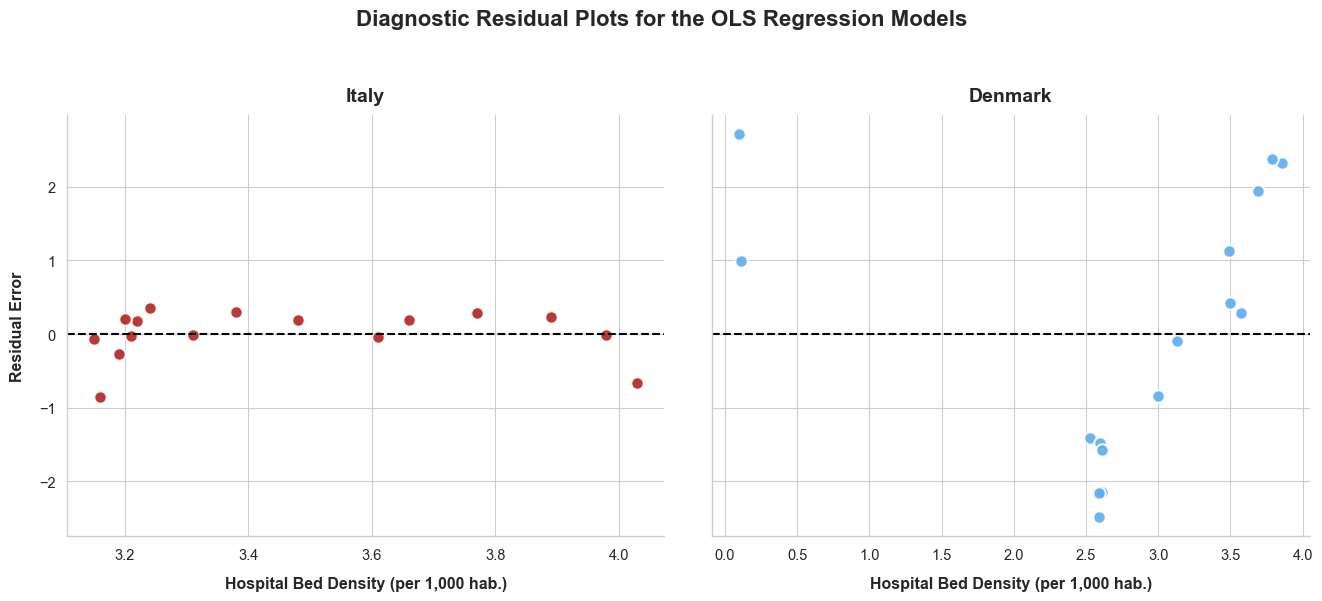

In [18]:
# === SEZIONE 6: GRAFICO 4 (Residuals Analysis) ===
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# Creazione figura con asse Y condiviso
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

df_ita = df_master[df_master['Country_ISO'] == 'ITA'].copy()
df_dnk = df_master[df_master['Country_ISO'] == 'DNK'].copy()

# --- Calcolo Residui Italia ---
slope_ita, intcpt_ita, _, _, _ = linregress(df_ita['Hospital_Beds_Density'], df_ita['AMI_Mortality_Rate'])
df_ita['Predicted'] = (df_ita['Hospital_Beds_Density'] * slope_ita) + intcpt_ita
df_ita['Residuals'] = df_ita['AMI_Mortality_Rate'] - df_ita['Predicted']

# --- Calcolo Residui Danimarca ---
slope_dnk, intcpt_dnk, _, _, _ = linregress(df_dnk['Hospital_Beds_Density'], df_dnk['AMI_Mortality_Rate'])
df_dnk['Predicted'] = (df_dnk['Hospital_Beds_Density'] * slope_dnk) + intcpt_dnk
df_dnk['Residuals'] = df_dnk['AMI_Mortality_Rate'] - df_dnk['Predicted']

# --- Plot Residui Italia ---
sns.scatterplot(data=df_ita, x='Hospital_Beds_Density', y='Residuals', ax=axes[0],
                color='#B22222', s=80, edgecolor='white', linewidth=1.5, alpha=0.9)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5) # Linea dello zero
axes[0].set_title('Italy', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Residual Error', fontweight='bold', labelpad=10)
axes[0].set_xlabel('Hospital Bed Density (per 1,000 hab.)', fontweight='bold', labelpad=10)

# --- Plot Residui Danimarca ---
sns.scatterplot(data=df_dnk, x='Hospital_Beds_Density', y='Residuals', ax=axes[1],
                color='#5CACEE', s=80, edgecolor='white', linewidth=1.5, alpha=0.9)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5) # Linea dello zero
axes[1].set_title('Denmark', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('') # Nascondiamo la label Y per condivisione asse
axes[1].set_xlabel('Hospital Bed Density (per 1,000 hab.)', fontweight='bold', labelpad=10)

# Pulizia e spaziatura
sns.despine()
plt.tight_layout(pad=3.0)

# Titolo Generale
plt.suptitle("Diagnostic Residual Plots for the OLS Regression Models", 
             fontsize=16, fontweight='bold', y=1.05)

plt.show()